<a href="https://colab.research.google.com/github/Manawariqbal/Data-Analysis-Projects/blob/main/Food_Delivery_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
"""
4. Food Delivery Time Analysis (food_delivery.csv, 800 orders)
Question: “What makes deliveries late, and how does delay affect ratings?”

1:Spot the 5 outliers in delivery time with the IQR method in NumPy, then decide whether to remove them.
2:Fill the missing ratings.
3:Create an is_late column for deliveries over 45 minutes.
4:Show delivery time by traffic, weather, and time of day in box plots.
5:Plot distance against delivery time with a regression line.
6:Plot delivery time against rating.
7:Bonus: use np.polyfit to predict delivery time from distance.
"""

'\n4. Food Delivery Time Analysis (food_delivery.csv, 800 orders)\nQuestion: “What makes deliveries late, and how does delay affect ratings?”\n\n1:Spot the 5 outliers in delivery time with the IQR method in NumPy, then decide whether to remove them.\n2:Fill the missing ratings.\n3:Create an is_late column for deliveries over 45 minutes.\n4:Show delivery time by traffic, weather, and time of day in box plots.\n5:Plot distance against delivery time with a regression line.\n6:Plot delivery time against rating.\n7:Bonus: use np.polyfit to predict delivery time from distance.\n'

In [2]:
#Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('/content/food_delivery.csv')

In [3]:
df.head()
df.isna().sum()


,0
order_id,0
distance_km,0
prep_time_min,0
traffic,0
weather,0
time_of_day,0
delivery_time_min,0
rating,20


In [4]:
#Task 1:Spot the 5 outliers in delivery time with the IQR method in NumPy,
# then decide whether to remove them.
df
dt=df["delivery_time_min"].to_numpy()

q1,q3=np.percentile(dt,[25,75])
iqr=q3-q1
lower_bound=q1-(1.5*iqr)
upper_bound=q3+(1.5*iqr)

outliers=(dt<lower_bound) |( dt>upper_bound)

print("Bounds: ",round(lower_bound,2),round(upper_bound,2))
print("Outliers found: ",outliers.sum())

df=df[~outliers].reset_index(drop=True)

Bounds:  1.5 69.5
Outliers found:  27


In [5]:
df

,order_id,distance_km,prep_time_min,traffic,weather,time_of_day,delivery_time_min,rating
0,5001,6.6,17.0,Low,Clear,Evening,39.0,4.4
1,5002,6.9,18.0,Low,Rain,Evening,50.0,3.9
2,5003,10.1,13.0,High,Clear,Evening,60.0,4.1
3,5004,0.7,15.0,Low,Clear,Evening,10.0,5.0
4,5005,0.9,18.0,Medium,Clear,Afternoon,24.0,4.4
...,...,...,...,...,...,...,...,...
768,5796,0.5,14.0,Medium,Clear,Morning,20.0,5.0
769,5797,8.2,20.0,Low,Clear,Afternoon,57.0,4.2
770,5798,5.4,10.0,Low,Clear,Afternoon,33.0,5.0
771,5799,5.0,15.0,Low,Rain,Evening,36.0,4.8


In [6]:
#Task 2:Fill the missing ratings.
df.isnull().sum()
df["rating"]=df["rating"].fillna(df["rating"].median())

In [7]:
df.isnull().sum()

,0
order_id,0
distance_km,0
prep_time_min,0
traffic,0
weather,0
time_of_day,0
delivery_time_min,0
rating,0


In [8]:
#3:Create an is_late column for deliveries over 45 minutes.

df["is_late"]=np.where(df["delivery_time_min"]>45,1,0)

In [9]:
df

,order_id,distance_km,prep_time_min,traffic,weather,time_of_day,delivery_time_min,rating,is_late
0,5001,6.6,17.0,Low,Clear,Evening,39.0,4.4,0
1,5002,6.9,18.0,Low,Rain,Evening,50.0,3.9,1
2,5003,10.1,13.0,High,Clear,Evening,60.0,4.1,1
3,5004,0.7,15.0,Low,Clear,Evening,10.0,5.0,0
4,5005,0.9,18.0,Medium,Clear,Afternoon,24.0,4.4,0
...,...,...,...,...,...,...,...,...,...
768,5796,0.5,14.0,Medium,Clear,Morning,20.0,5.0,0
769,5797,8.2,20.0,Low,Clear,Afternoon,57.0,4.2,1
770,5798,5.4,10.0,Low,Clear,Afternoon,33.0,5.0,0
771,5799,5.0,15.0,Low,Rain,Evening,36.0,4.8,0


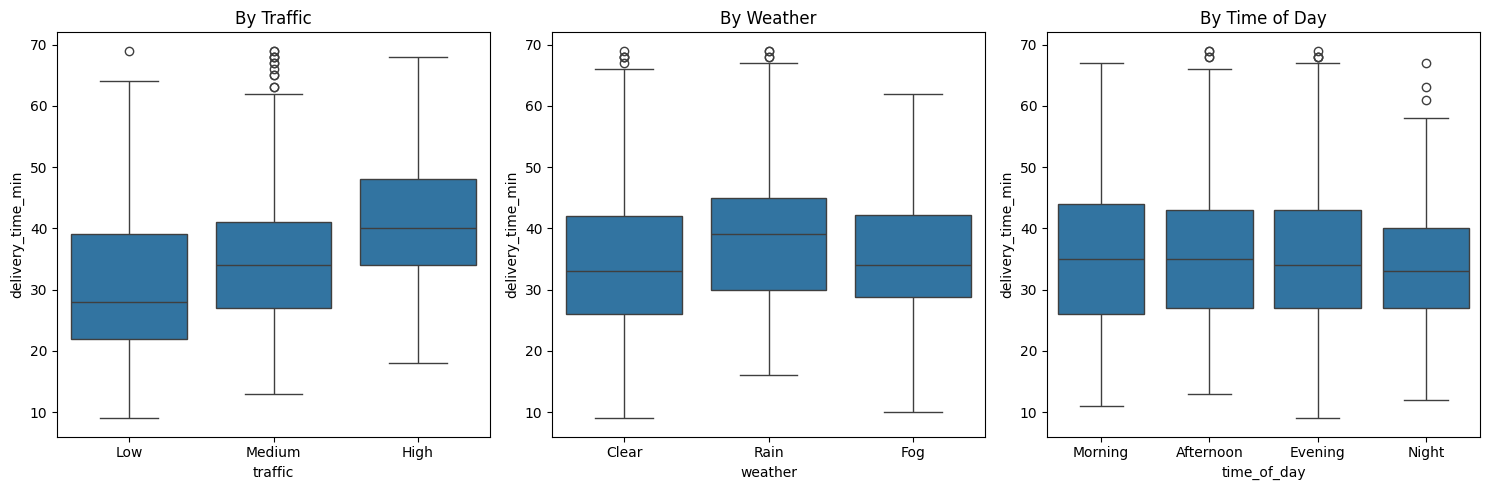

In [10]:
#4:Show delivery time by traffic, weather, and time of day in box plots.
fig,axes=plt.subplots(1,3,figsize=(15,5))
sns.boxplot(data=df,x="traffic",y="delivery_time_min",order=["Low","Medium","High"],ax=axes[0])
axes[0].set_title("By Traffic")
sns.boxplot(data=df,x="weather",y="delivery_time_min",ax=axes[1])
axes[1].set_title("By Weather")
sns.boxplot(data=df,x="time_of_day",y="delivery_time_min",order=["Morning","Afternoon","Evening","Night"],ax=axes[2])
axes[2].set_title("By Time of Day")
plt.tight_layout()
plt.show()

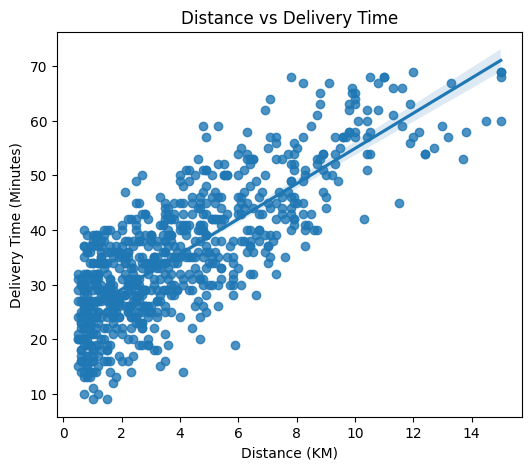

In [11]:
#Plot distance against delivery time with a regression line.
plt.figure(figsize=(6,5))
sns.regplot(data=df,x="distance_km",y="delivery_time_min")
plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (KM)")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

<Axes: xlabel='delivery_time_min', ylabel='rating'>

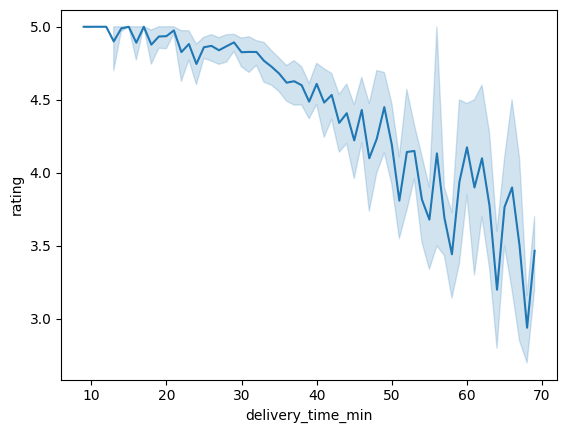

In [13]:
sns.lineplot(data = df , x = "delivery_time_min" , y = "rating")


In [14]:
#Bonus: use np.polyfit to predict delivery time from distance.
x = df["distance_km"]
y = df["delivery_time_min"]
slope, intercept = np.polyfit(x, y, 1)

print("Slope:", slope)
print("Intercept:", intercept)
distance = 5

predicted_time = slope * distance + intercept

print("Predicted Delivery Time:", predicted_time)

Slope: 3.2245577073473726
Intercept: 22.691288657797298
Predicted Delivery Time: 38.814077194534164


# Conclusions: Food Delivery Time Analysis

### 1. What makes deliveries late?
Based on our exploratory data analysis and visualization, several key factors influence delivery times:
* **Traffic**: High traffic levels significantly increase delivery times, as seen in the box plots. Deliveries during peak traffic are noticeably slower compared to low traffic.
* **Weather**: Adverse weather conditions (specifically Rain) shift the median delivery time higher compared to Clear or Foggy conditions.
* **Distance**: There is a strong, positive linear correlation between distance in kilometers and delivery time (as shown in our regression and `np.polyfit` analysis). On average, each additional kilometer adds approximately **3.22 minutes** to the delivery time, starting from a baseline setup/prep time of around **22.69 minutes**.

### 2. How does delay affect ratings?
* **The Rating Drop**: Looking at the line plot of `delivery_time_min` against `rating`, customer satisfaction remains consistently high (close to 5.0) for deliveries taking under 30 minutes.
* **The Turning Point**: Once delivery times exceed 30–35 minutes, ratings start to drop steadily.
* **Late Deliveries (Over 45 Minutes)**: When deliveries cross the 45-minute mark (`is_late = 1`), ratings drop sharply, falling from averages above 4.5 down toward 3.0 to 3.5. This shows a clear negative correlation between longer waiting times and user satisfaction.